# Week 7 — Anatomy of a Physics Engine
### Complete, runnable reference code

**Physics 311: Mechanics — Modeling, Computing, Publishing**

---

This notebook is the executable companion to the Week 7 lesson. It uses the `lab07_engine` Python package, plus the validation runs that prove it reproduces Labs 1–6.

Run it top to bottom (**Kernel &rarr; Restart & Run All**).

---

## The one idea

Six labs, one repeated skeleton: *set up state &rarr; loop over time &rarr; compute forces &rarr; integrate &rarr; record &rarr; plot.*

An **engine** writes it once and lets you plug in what changes.

| What changed between labs | Component that owns it |
|---|---|
| The objects (mass, radius, position, orientation) | `Body` |
| The interactions (gravity, springs, drag, contact) | `Force` objects in a registry |
| The update rule (Euler, Euler-Cromer, Verlet) | `Integrator` |
| Time stepping and bookkeeping | `World` |

The test of success: **a new simulation should be a new `main`, not a new engine.**

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import ellipk
from scipy.signal import argrelmin
import time

from lab07_engine import (
    Body, World,
    Force, Gravity, Drag, Spring, NewtonGravity, PivotGravityTorque, Wind,
    Euler, EulerCromer, VelocityVerlet,
    resolve_pair, CircleCollisions, BoxWalls
)

plt.rcParams['figure.figsize'] = (11, 4)
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.3
UT_ORANGE = '#ff8200'

print("NumPy", np.__version__)
print("Engine loaded successfully!")

NumPy 2.4.4
Engine loaded successfully!


---
## 1 &nbsp; `Body` — what the world is made of

A body owns **state** (position, velocity, orientation, spin) and **parameters** (mass, radius, moment of inertia). It owns no physics.

In [2]:
b = Body(m=2.0, r=(1, 2), v=(3, -1), radius=0.5, I=0.25, omega=4.0, name="test")
print(b)
print(f"  KE        = {b.ke():.4f} J")
print(f"  p         = {b.p()}")
print(f"  L (origin)= {b.L_about():.4f}")
print(f"  inv_m     = {b.inv_m:.4f}")

wall = Body(m=1.0, fixed=True, name="wall")
print(f"\n  fixed body inv_m = {wall.inv_m}  <- immovable by arithmetic")

Body(test, m=2.0, r=[1. 2.], v=[ 3. -1.])
  KE        = 12.0000 J
  p         = [ 6. -2.]
  L (origin)= -13.0000
  inv_m     = 0.5000

  fixed body inv_m = 0.0  <- immovable by arithmetic


---
## 2 &nbsp; `Force` — the registry and polymorphism

Every force exposes the same interface (`apply` and `potential_energy`).

In [3]:
print("Forces loaded from package:", [c.__name__ for c in
      (Gravity, Drag, Spring, NewtonGravity, PivotGravityTorque, Wind)])

Forces loaded from package: ['Gravity', 'Drag', 'Spring', 'NewtonGravity', 'PivotGravityTorque', 'Wind']


---
## 3 &nbsp; `Integrator` — swap the method, not the simulation

All three integrators share one signature: `step(world, dt)`.

In [4]:
print("Integrators:", [c.name for c in (Euler, EulerCromer, VelocityVerlet)])

Integrators: ['Euler', 'Euler-Cromer', 'Velocity Verlet']


---
## 4 &nbsp; Constraints — collisions as a separate stage

In [5]:
print("Constraints loaded: CircleCollisions, BoxWalls")

Constraints loaded: CircleCollisions, BoxWalls


---
## 5 &nbsp; `World` — the five-stage loop

In [6]:
w_test = World()
print("World initialized from package.")

World initialized from package.


---
# 6 &nbsp; Validation: reproduce Labs 1–6

Testing that the engine package reproduces expected physical behavior.

## 6.1 &nbsp; Labs 1–2: projectile

PROJECTILE  v0 = 25 m/s at 45 deg, Velocity Verlet, dt = 1e-3
  E0                = 312.5000000000 J
  max|dE|/E0        = 1.528e-14
  range (simulated) = 63.7105 m
  range (theory)    = 63.7105 m


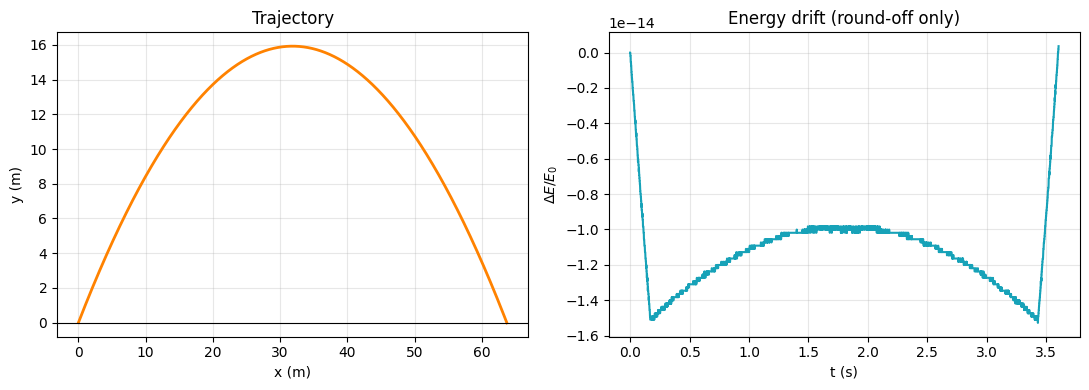

In [7]:
v0, angle = 25.0, 45.0
th = np.radians(angle)

w = World(integrator=VelocityVerlet())
w.add(Body(m=1.0, r=(0, 0), v=(v0*np.cos(th), v0*np.sin(th)), name="ball"))
w.add_force(Gravity(9.81))

w.record('t', lambda W: W.t)
w.record('x', lambda W: W.bodies[0].r[0])
w.record('y', lambda W: W.bodies[0].r[1])
w.record('E', lambda W: W.total_energy())

h = w.run(dt=0.001, t_end=3.606)
x, y, E = h['x'], h['y'], h['E']

i    = np.where(y < 0)[0][0]
frac = y[i-1] / (y[i-1] - y[i])
R    = x[i-1] + frac * (x[i] - x[i-1])

print("PROJECTILE  v0 = 25 m/s at 45 deg, Velocity Verlet, dt = 1e-3")
print(f"  E0                = {E[0]:.10f} J")
print(f"  max|dE|/E0        = {np.max(np.abs(E-E[0]))/abs(E[0]):.3e}")
print(f"  range (simulated) = {R:.4f} m")
print(f"  range (theory)    = {v0**2*np.sin(2*th)/9.81:.4f} m")

fig, ax = plt.subplots(1, 2)
ax[0].plot(x[:i+1], y[:i+1], color=UT_ORANGE, lw=2)
ax[0].axhline(0, color='k', lw=0.8); ax[0].set_xlabel('x (m)')
ax[0].set_ylabel('y (m)'); ax[0].set_title('Trajectory')
ax[1].plot(h['t'][:i+1], (E[:i+1]-E[0])/E[0], color='#17a2b8')
ax[1].set_xlabel('t (s)'); ax[1].set_ylabel(r'$\Delta E/E_0$')
ax[1].set_title('Energy drift (round-off only)')
plt.tight_layout(); plt.show()

## 6.2 &nbsp; Lab 3: the integrator showdown

SHO  k = m = 1, x0 = 1, 10 periods, dt = 0.05
integrator            max|dE|/E0     final x
Euler                 2.2071e+01      4.8004
Euler-Cromer          2.5641e-02      0.9991
Velocity Verlet       6.2500e-04      0.9997


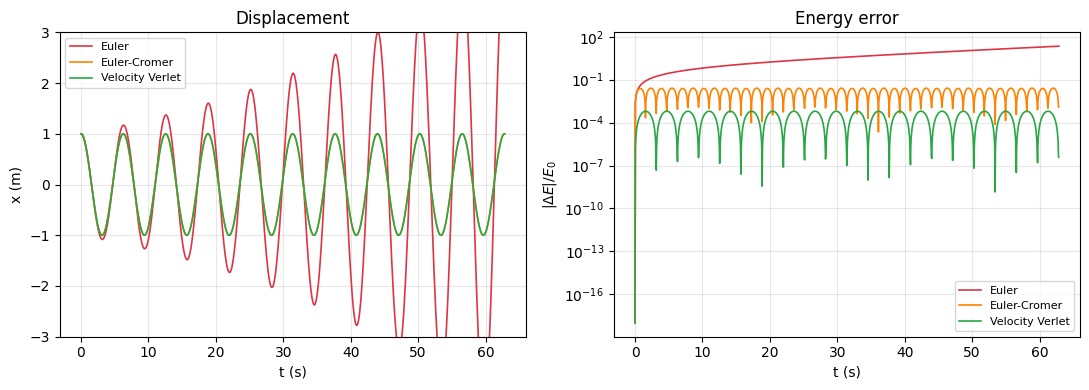

In [8]:
T_sho = 2*np.pi
rows = []

for Int in (Euler, EulerCromer, VelocityVerlet):
    w = World(integrator=Int())
    w.add(Body(m=1.0, r=(0, 0), fixed=True))
    w.add(Body(m=1.0, r=(1, 0), v=(0, 0)))
    w.add_force(Spring(0, 1, k=1.0, L0=0.0))
    w.record('t', lambda W: W.t)
    w.record('x', lambda W: W.bodies[1].r[0])
    w.record('E', lambda W: W.total_energy())
    h = w.run(dt=0.05, t_end=10*T_sho)
    rows.append((Int.name, h))

print("SHO  k = m = 1, x0 = 1, 10 periods, dt = 0.05")
print(f"{'integrator':<18}{'max|dE|/E0':>14}{'final x':>12}")
for name, h in rows:
    E = h['E']
    print(f"{name:<18}{np.max(np.abs(E-E[0]))/abs(E[0]):>14.4e}{h['x'][-1]:>12.4f}")

fig, ax = plt.subplots(1, 2)
for (name, h), c in zip(rows, ['#dc3545', UT_ORANGE, '#28a745']):
    ax[0].plot(h['t'], h['x'], label=name, lw=1.2, color=c)
    ax[1].semilogy(h['t'], np.abs(h['E']-h['E'][0])/h['E'][0] + 1e-18,
                   label=name, lw=1.2, color=c)
ax[0].set_xlabel('t (s)'); ax[0].set_ylabel('x (m)'); ax[0].set_title('Displacement')
ax[0].set_ylim(-3, 3); ax[0].legend(fontsize=8)
ax[1].set_xlabel('t (s)'); ax[1].set_ylabel(r'$|\Delta E|/E_0$')
ax[1].set_title('Energy error'); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 6.3 &nbsp; Lab 5: orbits and Kepler's third law

ORBIT  G = M = 1, r0 = (1,0), v0 = (0,0.8), dt = 1e-3, t = 20
integrator           max|dE/E0|   max|dL/L0|    r_min    r_max
Euler                 1.263e-01    5.476e-02   0.4752   1.1416
Euler-Cromer          9.763e-04    8.470e-15   0.4706   1.0000
Velocity Verlet       2.132e-06    5.956e-15   0.4706   1.0000


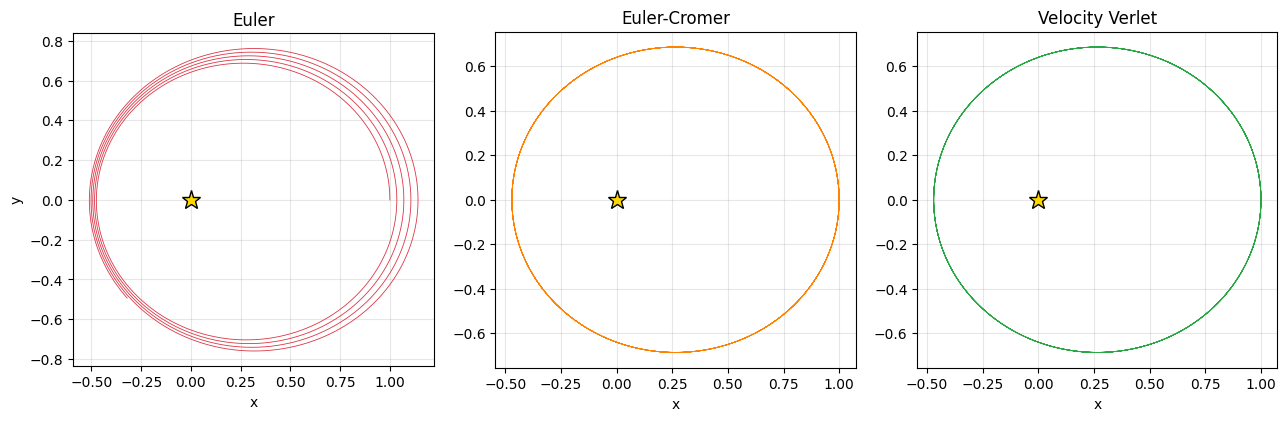

In [9]:
print("ORBIT  G = M = 1, r0 = (1,0), v0 = (0,0.8), dt = 1e-3, t = 20")
print(f"{'integrator':<18}{'max|dE/E0|':>13}{'max|dL/L0|':>13}{'r_min':>9}{'r_max':>9}")

trajs = []
for Int in (Euler, EulerCromer, VelocityVerlet):
    w = World(integrator=Int())
    w.add(Body(m=1.0,  r=(0, 0), fixed=True, name="star"))
    w.add(Body(m=1e-6, r=(1, 0), v=(0, 0.8), name="planet"))
    w.add_force(NewtonGravity(G=1.0))
    w.record('x', lambda W: W.bodies[1].r[0])
    w.record('y', lambda W: W.bodies[1].r[1])
    w.record('r', lambda W: np.linalg.norm(W.bodies[1].r))
    w.record('E', lambda W: W.total_energy())
    w.record('L', lambda W: W.angular_momentum())
    h = w.run(dt=0.001, t_end=20.0)
    E, L, r = h['E'], h['L'], h['r']
    print(f"{Int.name:<18}{np.max(np.abs(E-E[0]))/abs(E[0]):>13.3e}"
          f"{np.max(np.abs(L-L[0]))/abs(L[0]):>13.3e}{r.min():>9.4f}{r.max():>9.4f}")
    trajs.append((Int.name, h))

fig, ax = plt.subplots(1, 3, figsize=(13, 4))
for a, (name, h), c in zip(ax, trajs, ['#dc3545', UT_ORANGE, '#28a745']):
    a.plot(h['x'], h['y'], lw=0.6, color=c)
    a.plot(0, 0, '*', ms=14, color='gold', mec='k')
    a.set_aspect('equal'); a.set_title(name); a.set_xlabel('x')
ax[0].set_ylabel('y')
plt.tight_layout(); plt.show()

In [10]:
# Kepler's third law, measured
w = World(integrator=VelocityVerlet())
w.add(Body(m=1.0,  r=(0, 0), fixed=True))
w.add(Body(m=1e-6, r=(1, 0), v=(0, 0.8)))
w.add_force(NewtonGravity(G=1.0))
w.record('t', lambda W: W.t)
w.record('r', lambda W: np.linalg.norm(W.bodies[1].r))
h = w.run(dt=0.0005, t_end=20.0)
r, t = h['r'], h['t']

a_meas = (r.min() + r.max()) / 2
E_sp   = 0.5*0.8**2 - 1.0            # specific orbital energy
a_th   = -1 / (2*E_sp)
idx    = argrelmin(r, order=50)[0]
T_meas = np.mean(np.diff(t[idx]))

print("KEPLER CHECK  (Velocity Verlet, dt = 5e-4)")
print(f"  perihelion            = {r.min():.6f}")
print(f"  aphelion              = {r.max():.6f}")
print(f"  a  (measured)         = {a_meas:.6f}")
print(f"  a  (theory, -1/2E)    = {a_th:.6f}")
print(f"  T  (measured)         = {T_meas:.6f}")
print(f"  T  (Kepler 2*pi*a^3/2)= {2*np.pi*a_th**1.5:.6f}")

KEPLER CHECK  (Velocity Verlet, dt = 5e-4)
  perihelion            = 0.470588
  aphelion              = 1.000000
  a  (measured)         = 0.735294
  a  (theory, -1/2E)    = 0.735294
  T  (measured)         = 3.961500
  T  (Kepler 2*pi*a^3/2)= 3.961608


## 6.4 &nbsp; Lab 4: collisions

In [11]:
def collision_scene(e, walls=True):
    coll = CircleCollisions(e=e)
    cons = [coll]
    wl   = BoxWalls(0, 10, 0, 10, e=1.0) if walls else None
    if wl: cons.append(wl)
    w = World(integrator=EulerCromer(), constraints=cons)
    for p, v in zip([(2,2), (8,2), (2,8), (8,8)],
                    [(3,2), (-2,3), (2.5,-1.5), (-3,-2)]):
        w.add(Body(m=1.0, r=p, v=v, radius=0.5))
    return w, coll, wl

print("ISOLATED (walls off), t = 6 s -- momentum must hold")
print(f"{'e':>5}{'|dp|/|p0|':>14}{'KE retained':>14}{'pair hits':>11}")
for e in (1.0, 0.9, 0.5, 0.0):
    w, coll, _ = collision_scene(e, walls=False)
    p0, KE0 = w.momentum().copy(), w.kinetic_energy()
    w.run(dt=0.002, t_end=6.0)
    dp = np.linalg.norm(w.momentum()-p0) / np.linalg.norm(p0)
    print(f"{e:>5.1f}{dp:>14.3e}{100*w.kinetic_energy()/KE0:>13.2f}%{coll.count:>11d}")

print("\nIN A BOX (walls on), t = 20 s -- walls are EXTERNAL")
print(f"{'e':>5}{'KE retained':>14}{'pair hits':>11}{'wall hits':>11}")
for e in (1.0, 0.9, 0.5, 0.0):
    w, coll, wl = collision_scene(e)
    KE0 = w.kinetic_energy()
    w.run(dt=0.002, t_end=20.0)
    print(f"{e:>5.1f}{100*w.kinetic_energy()/KE0:>13.3f}%{coll.count:>11d}{wl.count:>11d}")

ISOLATED (walls off), t = 6 s -- momentum must hold
    e     |dp|/|p0|   KE retained  pair hits
  1.0     0.000e+00       100.00%          4
  0.9     2.809e-16        83.79%          4
  0.5     1.404e-16        48.03%          3
  0.0     2.809e-16        55.65%          3

IN A BOX (walls on), t = 20 s -- walls are EXTERNAL
    e   KE retained  pair hits  wall hits
  1.0      100.000%         10         37
  0.9       63.800%         10         31
  0.5       11.837%          8         18
  0.0       12.795%         11         20


## 6.5 &nbsp; Lab 6: the physical pendulum

In [12]:
m_rod, L_rod, g = 1.0, 1.0, 9.81
I_rod = m_rod * L_rod**2 / 3
d_cm  = L_rod / 2
Omega = np.sqrt(m_rod * g * d_cm / I_rod)

print(f"Rod about one end:  Omega = sqrt(3g/2L) = {Omega:.6f} rad/s")
print(f"                    T0    = {2*np.pi/Omega:.6f} s\n")
print(f"{'theta0':>8}{'T (engine)':>13}{'T (exact)':>13}{'rel err':>11}{'T/T0':>8}")

for th0 in (0.1, 0.3, 1.0, 2.0, 3.0):
    w = World(integrator=EulerCromer())
    w.add(Body(m=m_rod, r=(0, 0), I=I_rod, theta=th0, omega=0.0, name="rod"))
    w.add_force(PivotGravityTorque(0, m_rod, g, d_cm))
    w.record('t',  lambda W: W.t)
    w.record('th', lambda W: W.bodies[0].theta)
    h = w.run(dt=1e-4, t_end=12.0)

    th, t = h['th'], h['t']
    s     = np.sign(th)
    cross = np.where((s[:-1] > 0) & (s[1:] <= 0))[0]
    tc    = [t[i] + th[i]/(th[i]-th[i+1])*(t[i+1]-t[i]) for i in cross]
    T_sim = np.mean(np.diff(tc))
    T_ex  = 4/Omega * ellipk(np.sin(th0/2)**2)

    print(f"{th0:>8.1f}{T_sim:>13.6f}{T_ex:>13.6f}"
          f"{abs(T_sim-T_ex)/T_ex:>11.2e}{T_sim/(2*np.pi/Omega):>8.4f}")

Rod about one end:  Omega = sqrt(3g/2L) = 3.836014 rad/s
                    T0    = 1.637947 s

  theta0   T (engine)    T (exact)    rel err    T/T0
     0.1     1.638971     1.638971   6.10e-09  1.0006
     0.3     1.647208     1.647208   5.86e-09  1.0057
     1.0     1.746599     1.746599   3.31e-09  1.0663
     2.0     2.176675     2.176675   2.55e-09  1.3289
     3.0     4.211544     4.211544   6.07e-09  2.5712


---
# 7 &nbsp; The payoff: figure-eight three-body orbit

FIGURE-EIGHT THREE-BODY ORBIT   4 periods, Verlet, dt = 1e-4
  E0                   = -1.287141992
  max|dE/E0|           = 5.892e-09
  max|p|  (exact 0)    = 3.482e-14
  max|dL| (exact 0)    = 3.354e-14
  |r_A(4T) - r_A(0)|   = 2.788e-05


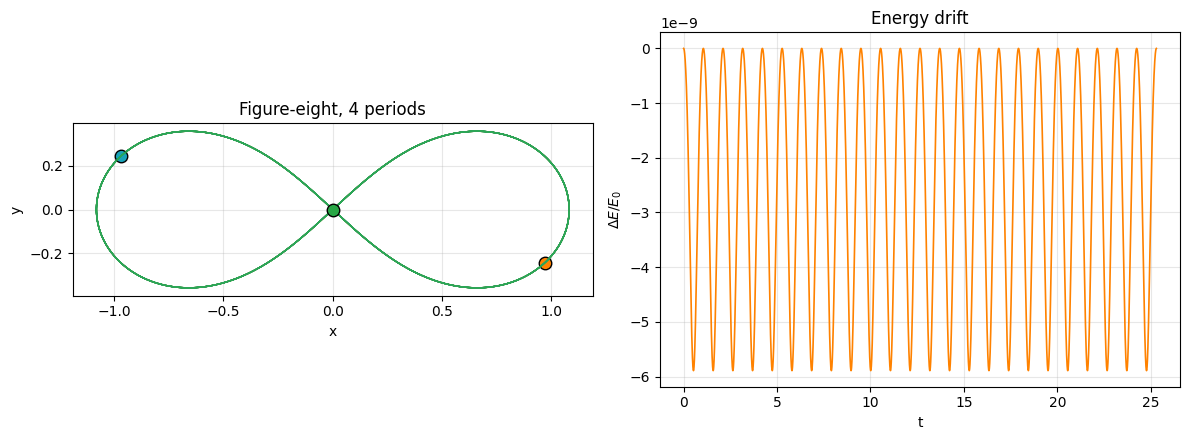

In [13]:
x1, y1   = 0.97000436, -0.24308753
vx3, vy3 = -0.93240737, -0.86473146
T_fig    = 6.32591398

w = World(integrator=VelocityVerlet())
w.add(Body(m=1, r=( x1,  y1), v=(-vx3/2, -vy3/2), name="A"))
w.add(Body(m=1, r=(-x1, -y1), v=(-vx3/2, -vy3/2), name="B"))
w.add(Body(m=1, r=(  0,   0), v=( vx3,    vy3  ), name="C"))
w.add_force(NewtonGravity(G=1.0))

for i in range(3):
    w.record(f'x{i}', lambda W, i=i: W.bodies[i].r[0])
    w.record(f'y{i}', lambda W, i=i: W.bodies[i].r[1])
w.record('t', lambda W: W.t)
w.record('E', lambda W: W.total_energy())
w.record('p', lambda W: np.linalg.norm(W.momentum()))
w.record('L', lambda W: W.angular_momentum())

h = w.run(dt=1e-4, t_end=4*T_fig, capture_every=10)
E, p, L = h['E'], h['p'], h['L']

print("FIGURE-EIGHT THREE-BODY ORBIT   4 periods, Verlet, dt = 1e-4")
print(f"  E0                   = {E[0]:.9f}")
print(f"  max|dE/E0|           = {np.max(np.abs(E-E[0]))/abs(E[0]):.3e}")
print(f"  max|p|  (exact 0)    = {p.max():.3e}")
print(f"  max|dL| (exact 0)    = {np.max(np.abs(L-L[0])):.3e}")
print(f"  |r_A(4T) - r_A(0)|   = {np.linalg.norm(w.bodies[0].r-np.array([x1,y1])):.3e}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for i, c in enumerate([UT_ORANGE, '#17a2b8', '#28a745']):
    ax[0].plot(h[f'x{i}'], h[f'y{i}'], lw=1.0, color=c, alpha=0.8)
    ax[0].plot(w.bodies[i].r[0], w.bodies[i].r[1], 'o', ms=9, color=c, mec='k')
ax[0].set_aspect('equal'); ax[0].set_title('Figure-eight, 4 periods')
ax[0].set_xlabel('x'); ax[0].set_ylabel('y')
ax[1].plot(h['t'], (E-E[0])/abs(E[0]), color=UT_ORANGE, lw=1.2)
ax[1].set_xlabel('t'); ax[1].set_ylabel(r'$\Delta E/E_0$')
ax[1].set_title('Energy drift')
plt.tight_layout(); plt.show()

---
## 8 &nbsp; What it costs: $O(N^2)$

In [14]:
print("NewtonGravity + Verlet, 200 steps")
print(f"{'N':>5}{'pairs':>8}{'time (s)':>11}{'ratio':>8}")
prev = None
for N in (10, 20, 40, 80):
    w   = World(integrator=VelocityVerlet())
    rng = np.random.default_rng(3)
    for _ in range(N):
        w.add(Body(m=1.0, r=rng.uniform(-5, 5, 2), v=rng.uniform(-.1, .1, 2)))
    w.add_force(NewtonGravity(G=1.0, soft=0.5))
    t0 = time.perf_counter()
    for _ in range(200):
        w.step(0.001)
    el = time.perf_counter() - t0
    r  = f"{el/prev:.2f}" if prev else "--"
    print(f"{N:>5}{N*(N-1)//2:>8}{el:>11.4f}{r:>8}")
    prev = el

NewtonGravity + Verlet, 200 steps
    N   pairs   time (s)   ratio
   10      45     0.0388      --
   20     190     0.1301    3.35
   40     780     0.5012    3.85
   80    3160     1.9321    3.86


---
## 9 &nbsp; Fixed timestep: the accumulator

In [15]:
DT, T_TOTAL = 1/240, 10.0

def spring_scene():
    w = World(integrator=VelocityVerlet())
    w.add(Body(m=1.0, r=(0, 0), fixed=True))
    w.add(Body(m=1.0, r=(1.0, 0.0), v=(0.0, 0.0)))
    w.add_force(Spring(0, 1, k=4.0, L0=0.0))
    return w

def patterns(total):
    rng = np.random.default_rng(11)
    out = {"steady 60 fps": np.full(int(total*60), 1/60)}
    j = rng.uniform(1/144, 1/24, 4000); j = j[np.cumsum(j) <= total]
    out["jittery 24-144"] = np.append(j, total - j.sum())
    s = np.full(int(total*60), 1/60); s[::37] = 0.25
    s = s[np.cumsum(s) <= total]
    out["60 fps + stalls"] = np.append(s, total - s.sum())
    return out

exact = np.cos(2.0 * T_TOTAL)

print("FIXED TIMESTEP ACCUMULATOR")
print(f"{'frame pattern':<18}{'frames':>8}{'steps':>8}{'x(10 s)':>16}")
for label, frames in patterns(T_TOTAL).items():
    w, acc, steps = spring_scene(), 0.0, 0
    for ft in frames:
        acc += min(ft, 0.25)
        while acc >= DT:
            w.step(DT); acc -= DT; steps += 1
    print(f"{label:<18}{len(frames):>8}{steps:>8}{w.bodies[1].r[0]:>16.10f}")

print("\nNAIVE VARIABLE TIMESTEP  (step once per frame, dt = frame time)")
print(f"{'frame pattern':<18}{'frames':>8}{'x(10 s)':>16}{'error':>12}")
for label, frames in patterns(T_TOTAL).items():
    w = spring_scene()
    for ft in frames:
        w.step(min(ft, 0.25))
    x = w.bodies[1].r[0]
    print(f"{label:<18}{len(frames):>8}{x:>16.10f}{abs(x-exact):>12.2e}")
print(f"\n  exact x(10 s) = {exact:.10f}")

FIXED TIMESTEP ACCUMULATOR
frame pattern       frames   steps         x(10 s)
steady 60 fps          600    2400    0.4080292282
jittery 24-144         426    2400    0.4080292282
60 fps + stalls        432    2399    0.4156230684

NAIVE VARIABLE TIMESTEP  (step once per frame, dt = frame time)
frame pattern       frames         x(10 s)       error
steady 60 fps          600    0.4072364616    8.46e-04
jittery 24-144         426    0.4056113515    2.47e-03
60 fps + stalls        432    0.3565970871    5.15e-02

  exact x(10 s) = 0.4080820618


---
## 10 &nbsp; The architecture test

Lines added to Body / Force / Integrator / World:  0
x at t = 4 s   no wind:  40.0000 m
               2 N headwind:  24.0000 m


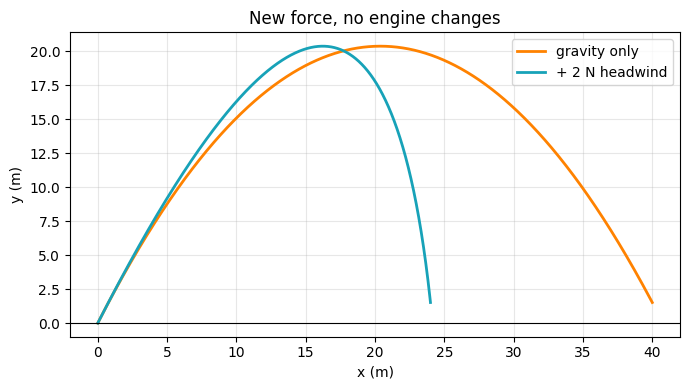

In [16]:
w = World(integrator=VelocityVerlet())
w.add(Body(m=1.0, r=(0, 0), v=(10, 20)))
w.add_force(Gravity(9.81))
w.add_force(Wind((-2.0, 0.0)))
w.record('x', lambda W: W.bodies[0].r[0])
w.record('y', lambda W: W.bodies[0].r[1])
h = w.run(dt=0.001, t_end=4.0)

w2 = World(integrator=VelocityVerlet())
w2.add(Body(m=1.0, r=(0, 0), v=(10, 20)))
w2.add_force(Gravity(9.81))
w2.record('x', lambda W: W.bodies[0].r[0])
w2.record('y', lambda W: W.bodies[0].r[1])
h2 = w2.run(dt=0.001, t_end=4.0)

print("Lines added to Body / Force / Integrator / World:  0")
print(f"x at t = 4 s   no wind: {h2['x'][-1]:8.4f} m")
print(f"               2 N headwind: {h['x'][-1]:8.4f} m")

plt.figure(figsize=(7, 4))
plt.plot(h2['x'], h2['y'], lw=2, color=UT_ORANGE, label='gravity only')
plt.plot(h['x'],  h['y'],  lw=2, color='#17a2b8', label='+ 2 N headwind')
plt.axhline(0, color='k', lw=0.8); plt.xlabel('x (m)'); plt.ylabel('y (m)')
plt.legend(); plt.title('New force, no engine changes'); plt.ylim(bottom=-1)
plt.tight_layout(); plt.show()


## Part A: Building the Physics Engine

For Part A, the goal is to take the physics we have worked with in previous labs and put it into one engine that can be reused for different simulations. Instead of having to rewrite the code every time, we can define the bodies, forces, and integration method separately.

The engine is made up of four main components:

- **Body:** Holds information such as mass, position, velocity, and rotational motion.

- **Force:** Calculates the forces acting on each body, including gravity, drag, and springs.

- **Integrator:** Determines how position and velocity are updated over time.

- **World:** Brings everything together, runs the simulation, and records the results.

The engine also handles collisions separately from the forces, which makes it easier to add different interactions later.

## Class Diagram

                  World
                    |
         -----------------------
         |          |          |
        Body       Force    Integrator
         |          |          |
      Position    Gravity      Euler
      Velocity    Drag         Euler-Cromer
      Mass        Spring       Verlet
      Rotation      |
                    |
                Collisions

## Part A Setup

To check that the engine is working correctly, I first tested the force calculations and made sure forces were not being counted multiple times between steps. I also checked that the engine could record quantities such as position, energy, and momentum.

After that, I compared two projectile simulations using the same initial conditions. The first used gravity alone, while the second included both gravity and air resistance. This allows for the visualization of whether the engine could handle multiple forces without changing the simulation code itself.


PART A - PHYSICS ENGINE
--------------------------------------------------
Engine imported successfully!

Force Calculations
Calculated force: [ -0.8  -20.22]
Expected force:   [ -0.8  -20.22]
Forces reset correctly: True
Forces match theory:    True

Recording Test
Recorded values: ['t', 'position', 'energy', 'momentum']
Final time: 0.500 s
Final position: [1.95072306 2.25452527]


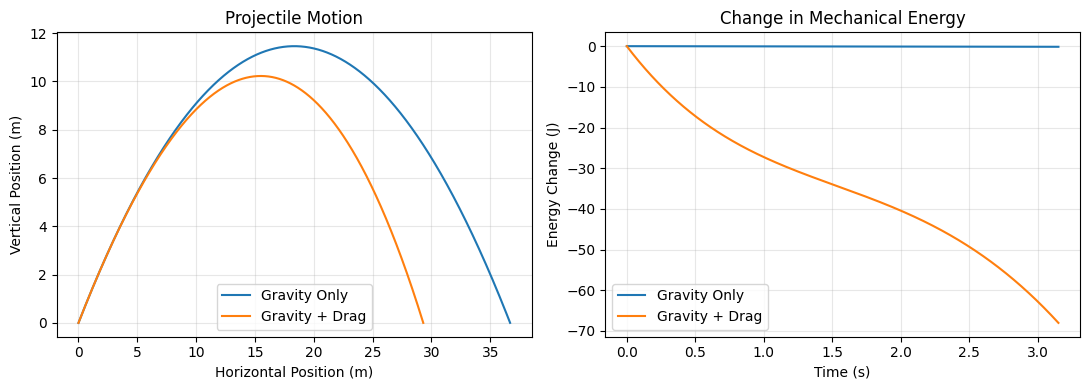


Energy Results
Gravity only maximum energy drift: 1.515719e-01 J
Gravity + drag energy change: -68.022213 J


In [17]:

# Part A - Physics Engine

import numpy as np
import matplotlib.pyplot as plt

from lab07_engine import (
    Body, World, Gravity, Drag, Spring, NewtonGravity,
    Euler, EulerCromer, VelocityVerlet,
    CircleCollisions, BoxWalls
)

print("PART A - PHYSICS ENGINE")
print("-" * 50)
print("Engine imported successfully!")

# Check force calculations

world = World(integrator=EulerCromer())

body = Body(
    m=2.0,
    r=(0.0, 2.0),
    v=(4.0, 3.0),
    name="Test Body"
)

world.add(body)
world.add_force(Gravity(g=9.81))
world.add_force(Drag(k=0.20, quadratic=False))

world.compute_forces()
force1 = body.f.copy()

world.compute_forces()
force2 = body.f.copy()

expected_force = np.array([
    -0.20 * 4.0,
    -2.0 * 9.81 - 0.20 * 3.0
])

print("\nForce Calculations")
print("Calculated force:", force1)
print("Expected force:  ", expected_force)
print("Forces reset correctly:", np.allclose(force1, force2))
print("Forces match theory:   ", np.allclose(force1, expected_force))


# Check the recording system

world.record('t', lambda w: w.t)
world.record('position', lambda w: w.bodies[0].r.copy())
world.record('energy', lambda w: w.total_energy())
world.record('momentum', lambda w: w.momentum().copy())

history = world.run(dt=0.001, t_end=0.5)

print("\nRecording Test")
print("Recorded values:", list(history.keys()))
print(f"Final time: {history['t'][-1]:.3f} s")
print(f"Final position: {history['position'][-1]}")

# Compare projectile motion with and without drag

def simulate_projectile(use_drag=False):

    w = World(integrator=EulerCromer())

    projectile = Body(
        m=1.0,
        r=(0.0, 0.0),
        v=(12.0, 15.0),
        name="Projectile"
    )

    w.add(projectile)
    w.add_force(Gravity(g=9.81))

    if use_drag:
        w.add_force(Drag(k=0.12, quadratic=False))

    w.record('t', lambda W: W.t)
    w.record('x', lambda W: W.bodies[0].r[0])
    w.record('y', lambda W: W.bodies[0].r[1])
    w.record('energy', lambda W: W.total_energy())

    return w.run(dt=0.001, t_end=3.15)

gravity_only = simulate_projectile(False)
gravity_drag = simulate_projectile(True)

# Plot the results

fig, ax = plt.subplots(1, 2, figsize=(11, 4))

for data, label, color in [
    (gravity_only, 'Gravity Only', 'tab:blue'),
    (gravity_drag, 'Gravity + Drag', 'tab:orange')
]:

    above_ground = data['y'] >= 0

    ax[0].plot(
        data['x'][above_ground],
        data['y'][above_ground],
        label=label,
        color=color
    )

    ax[1].plot(
        data['t'],
        data['energy'] - data['energy'][0],
        label=label,
        color=color
    )

ax[0].set_title("Projectile Motion")
ax[0].set_xlabel("Horizontal Position (m)")
ax[0].set_ylabel("Vertical Position (m)")
ax[0].legend()
ax[0].grid(True)

ax[1].set_title("Change in Mechanical Energy")
ax[1].set_xlabel("Time (s)")
ax[1].set_ylabel("Energy Change (J)")
ax[1].legend()
ax[1].grid(True)

plt.tight_layout()
plt.show()

# Print energy results

gravity_error = np.max(
    np.abs(gravity_only['energy'] - gravity_only['energy'][0])
)

drag_energy_change = (
    gravity_drag['energy'][-1] - gravity_drag['energy'][0]
)

print("\nEnergy Results")
print(f"Gravity only maximum energy drift: {gravity_error:.6e} J")
print(f"Gravity + drag energy change: {drag_energy_change:.6f} J")



## Part A Interpretation

The first test confirmed that the engine is calculating forces correctly! Both the calculated and expected forces were [-0.8, -20.22] N, and recalculating the forces gave the same result. This demonstrates that the force accumulator is being reset properly instead of continuing to add forces from previous steps. The engine also successfully recorded the position, energy, and momentum over time.

The projectile comparison showed the difference between gravity alone and gravity with drag. Without drag, the projectile followed the expected parabolic trajectory and had a maximum energy drift of about 0.152 J. This is relatively small compared to its initial energy. When drag was added, the projectile reached a lower height and traveled a shorter distance. The mechanical energy also decreased by about 68.02 J, which is expected given that drag removes energy from the system.

Overall, Part A demonstrates how useful the engine structure is for running different simulations. Furthermore, it made adding another force without changing the underlying code very easy.


## Part B: Validation Against Previous Labs

For Part B, the goal is to verify that the physics engine can reproduce the results from the previous labs. Rather than writing separate simulation code for each problem, we will use the same engine with different forces, initial conditions, and integration methods.

We will compare three different simulations:

1. **Projectile Motion (Labs 1 and 2):** Compare the simulated trajectory with the analytical solution and check for conservation of mechanical energy.

2. **Spring Oscillator (Lab 3):** Compare the simulated oscillations with the theoretical period and displacement, examine the phase-space ellipse, and monitor energy conservation.

3. **Orbital Motion (Lab 5):** Compare the simulated orbit with the expected elliptical trajectory and examine conservation of energy and angular momentum.

For each simulation, we will compare the numerical results against the theoretical predictions and calculate the corresponding errors. 

PART B - VALIDATION
-------------------------------------------------------

1. PROJECTILE MOTION
Simulated range:   63.71050 m
Theoretical range: 63.71050 m
Range error:       4.902e-08 m
Max energy error:  1.528e-14


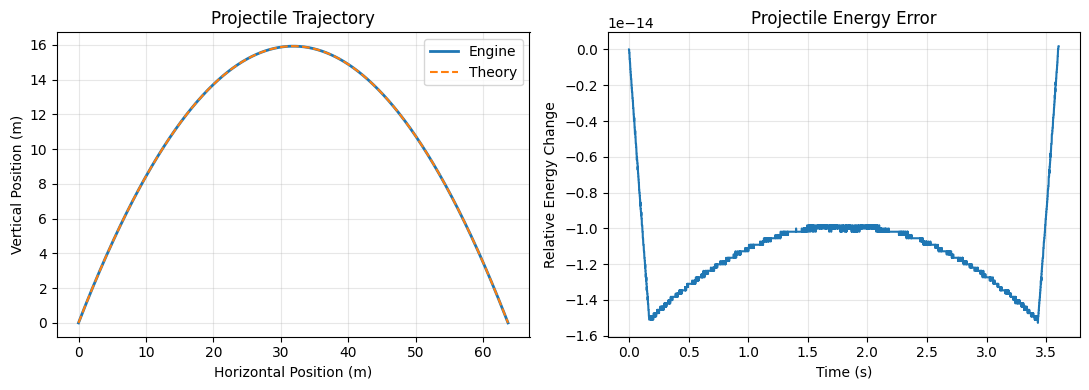


2. SPRING OSCILLATOR
Simulated period:   3.141500 s
Theoretical period: 3.141593 s
Relative period error: 2.949e-05
Max energy error:      1.000e-06


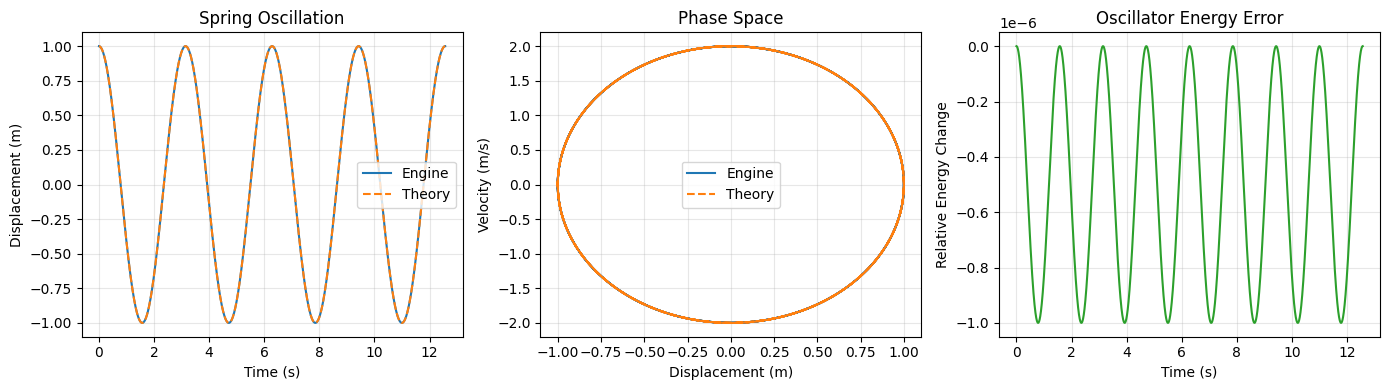


3. ORBITAL MOTION
Simulated semi-major axis:   0.735295
Theoretical semi-major axis: 0.735294
Eccentricity:                0.360000
Max energy error:            2.132e-06
Max angular momentum error:  3.044e-15


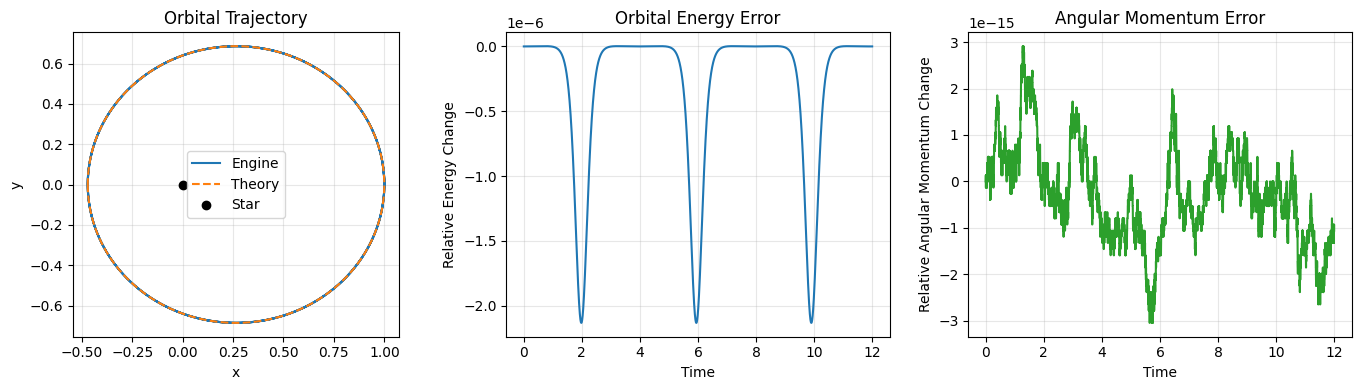

In [18]:

# Part B - Validation Against Previous Labs

import numpy as np
import matplotlib.pyplot as plt

from lab07_engine import (
    Body, World, Gravity, Spring, NewtonGravity,
    EulerCromer, VelocityVerlet
)

print("PART B - VALIDATION")
print("-" * 55)

# 1. Projectile Motion (Labs 1 and 2)

g = 9.81
v0 = 25.0
angle = np.radians(45.0)
vx0 = v0 * np.cos(angle)
vy0 = v0 * np.sin(angle)

world = World(integrator=VelocityVerlet())

world.add(Body(
    m=1.0,
    r=(0.0, 0.0),
    v=(vx0, vy0)
))

world.add_force(Gravity(g))

world.record('t', lambda w: w.t)
world.record('x', lambda w: w.bodies[0].r[0])
world.record('y', lambda w: w.bodies[0].r[1])
world.record('E', lambda w: w.total_energy())

projectile = world.run(dt=0.001, t_end=3.7)

t = projectile['t']
x = projectile['x']
y = projectile['y']
E = projectile['E']

x_theory = vx0 * t
y_theory = vy0 * t - 0.5 * g * t**2

flight_time = 2 * vy0 / g
range_theory = vx0 * flight_time

i = np.where(y < 0)[0][0]
fraction = y[i-1] / (y[i-1] - y[i])
range_sim = x[i-1] + fraction * (x[i] - x[i-1])

energy_error = np.max(np.abs(E - E[0])) / abs(E[0])

print("\n1. PROJECTILE MOTION")
print(f"Simulated range:   {range_sim:.5f} m")
print(f"Theoretical range: {range_theory:.5f} m")
print(f"Range error:       {abs(range_sim-range_theory):.3e} m")
print(f"Max energy error:  {energy_error:.3e}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))

valid = t <= flight_time

ax[0].plot(x[valid], y[valid],
           label='Engine', color='tab:blue', linewidth=2)
ax[0].plot(x_theory[valid], y_theory[valid], '--',
           label='Theory', color='tab:orange')

ax[0].set_title('Projectile Trajectory')
ax[0].set_xlabel('Horizontal Position (m)')
ax[0].set_ylabel('Vertical Position (m)')
ax[0].legend()
ax[0].grid(True)

ax[1].plot(t[valid], (E[valid]-E[0])/E[0],
           color='tab:blue')
ax[1].set_title('Projectile Energy Error')
ax[1].set_xlabel('Time (s)')
ax[1].set_ylabel('Relative Energy Change')
ax[1].grid(True)

plt.tight_layout()
plt.show()

# 2. Spring Oscillator (Lab 3)

m = 1.0
k = 4.0
x0 = 1.0
omega = np.sqrt(k / m)
period_theory = 2 * np.pi / omega

world = World(integrator=VelocityVerlet())

world.add(Body(
    m=1.0,
    r=(0.0, 0.0),
    fixed=True
))

world.add(Body(
    m=m,
    r=(x0, 0.0),
    v=(0.0, 0.0)
))

world.add_force(Spring(0, 1, k=k, L0=0.0))

world.record('t', lambda w: w.t)
world.record('x', lambda w: w.bodies[1].r[0])
world.record('v', lambda w: w.bodies[1].v[0])
world.record('E', lambda w: w.total_energy())

oscillator = world.run(dt=0.001, t_end=4*period_theory)

t = oscillator['t']
x = oscillator['x']
v = oscillator['v']
E = oscillator['E']

x_theory = x0 * np.cos(omega*t)
v_theory = -x0 * omega * np.sin(omega*t)

# Find the period using successive maxima
maxima = np.where(
    (x[1:-1] > x[:-2]) &
    (x[1:-1] > x[2:])
)[0] + 1

period_sim = np.mean(np.diff(t[maxima]))

period_error = abs(period_sim-period_theory)/period_theory
energy_error = np.max(np.abs(E-E[0]))/abs(E[0])

print("\n2. SPRING OSCILLATOR")
print(f"Simulated period:   {period_sim:.6f} s")
print(f"Theoretical period: {period_theory:.6f} s")
print(f"Relative period error: {period_error:.3e}")
print(f"Max energy error:      {energy_error:.3e}")

fig, ax = plt.subplots(1, 3, figsize=(14, 4))

ax[0].plot(t, x, label='Engine', color='tab:blue')
ax[0].plot(t, x_theory, '--',
           label='Theory', color='tab:orange')
ax[0].set_title('Spring Oscillation')
ax[0].set_xlabel('Time (s)')
ax[0].set_ylabel('Displacement (m)')
ax[0].legend()
ax[0].grid(True)

ax[1].plot(x, v, color='tab:blue', label='Engine')
ax[1].plot(x_theory, v_theory, '--',
           color='tab:orange', label='Theory')
ax[1].set_title('Phase Space')
ax[1].set_xlabel('Displacement (m)')
ax[1].set_ylabel('Velocity (m/s)')
ax[1].legend()
ax[1].grid(True)

ax[2].plot(t, (E-E[0])/E[0], color='tab:green')
ax[2].set_title('Oscillator Energy Error')
ax[2].set_xlabel('Time (s)')
ax[2].set_ylabel('Relative Energy Change')
ax[2].grid(True)

plt.tight_layout()
plt.show()

# 3. Orbital Motion (Lab 5)

G = 1.0
M = 1.0
r0 = 1.0
v0 = 0.8

world = World(integrator=VelocityVerlet())

world.add(Body(
    m=M,
    r=(0.0, 0.0),
    fixed=True,
    name="Star"
))

world.add(Body(
    m=1e-6,
    r=(r0, 0.0),
    v=(0.0, v0),
    name="Planet"
))

world.add_force(NewtonGravity(G=G))

world.record('t', lambda w: w.t)
world.record('x', lambda w: w.bodies[1].r[0])
world.record('y', lambda w: w.bodies[1].r[1])
world.record('r', lambda w: np.linalg.norm(w.bodies[1].r))
world.record('E', lambda w: w.total_energy())
world.record('L', lambda w: w.angular_momentum())

orbit = world.run(dt=0.001, t_end=12.0)

t = orbit['t']
x = orbit['x']
y = orbit['y']
r = orbit['r']
E = orbit['E']
L = orbit['L']

# Theoretical orbital parameters
mu = G * M
specific_energy = 0.5*v0**2 - mu/r0
a_theory = -mu/(2*specific_energy)
h_specific = r0*v0
eccentricity = np.sqrt(
    1 + 2*specific_energy*h_specific**2/mu**2
)

# The initial position is the aphelion
theta = np.linspace(0, 2*np.pi, 1000)
p = a_theory * (1-eccentricity**2)
r_theory = p/(1 + eccentricity*np.cos(theta))

x_theory = -r_theory*np.cos(theta)
y_theory = -r_theory*np.sin(theta)

a_sim = (r.min()+r.max())/2
energy_error = np.max(np.abs(E-E[0]))/abs(E[0])
momentum_error = np.max(np.abs(L-L[0]))/abs(L[0])

print("\n3. ORBITAL MOTION")
print(f"Simulated semi-major axis:   {a_sim:.6f}")
print(f"Theoretical semi-major axis: {a_theory:.6f}")
print(f"Eccentricity:                {eccentricity:.6f}")
print(f"Max energy error:            {energy_error:.3e}")
print(f"Max angular momentum error:  {momentum_error:.3e}")

fig, ax = plt.subplots(1, 3, figsize=(14, 4))

ax[0].plot(x, y, color='tab:blue', label='Engine')
ax[0].plot(x_theory, y_theory, '--',
           color='tab:orange', label='Theory')
ax[0].plot(0, 0, 'o', color='black', label='Star')
ax[0].set_aspect('equal')
ax[0].set_title('Orbital Trajectory')
ax[0].set_xlabel('x')
ax[0].set_ylabel('y')
ax[0].legend()
ax[0].grid(True)

ax[1].plot(t, (E-E[0])/abs(E[0]), color='tab:blue')
ax[1].set_title('Orbital Energy Error')
ax[1].set_xlabel('Time')
ax[1].set_ylabel('Relative Energy Change')
ax[1].grid(True)

ax[2].plot(t, (L-L[0])/abs(L[0]), color='tab:green')
ax[2].set_title('Angular Momentum Error')
ax[2].set_xlabel('Time')
ax[2].set_ylabel('Relative Angular Momentum Change')
ax[2].grid(True)

plt.tight_layout()
plt.show()


## Part B Interpretation

The three simulations were able to reproduce the expected results from the previous labs with relatively small numerical errors.

For the projectile, the simulated and theoretical trajectories overlapped almost perfectly, with a range difference of only 4.902e-8 m. The maximum relative energy error was also extremely small at 1.528e-14, showing that mechanical energy was essentially conserved throughout the simulation.

The spring oscillator produced similar results. The simulated period was 3.141500 s compared to the theoretical value of 3.141593 s. Both the displacement and phase-space plots matched the analytical solutions, and the maximum relative energy error was only 1.000e-6. This demonstraters that the engine was accurately reproducing the expected oscillatory motion without significant energy drift.

For the orbital simulation, the calculated semi-major axis was 0.735295 compared to the theoretical value of 0.735294. The orbital energy error was approximately 2.132e-6, while angular momentum was conserved to approximately 3.044e-15. These results indicate that Velocity Verlet is indeed effective at maintaining the expected orbital behavior.

Overall, Part B demonstrated that the same engine could reproduce several different physical systems without modifying the underlying classes. This was particularly useful in that the results themselves are also verifiable.



# Part C: Original Multi-Body Simulation

For Part C, I wanted to use the physics engine to simulate something far more complicated than the systems we have worked with in the previous labs. I decided to create a spring bridge consisting of five connected bodies, with the two ends fixed in place and the middle three free to move.

The simulation includes three different forces: gravity, springs, and linear drag. Gravity pulls the bodies downward, the springs resist changes in length, and drag gradually reduces the motion.

I used a spring constant of 35 N/m, a drag coefficient of 0.25 kg/s, and a simulation time of 12 seconds. Velocity Verlet was used to update the motion.

To check the results, I plotted the bridge at different times, tracked the vertical motion of the middle body, and compared the change in mechanical energy with the work done by drag.

PART C - MULTI-BODY SPRING BRIDGE
-------------------------------------------------------


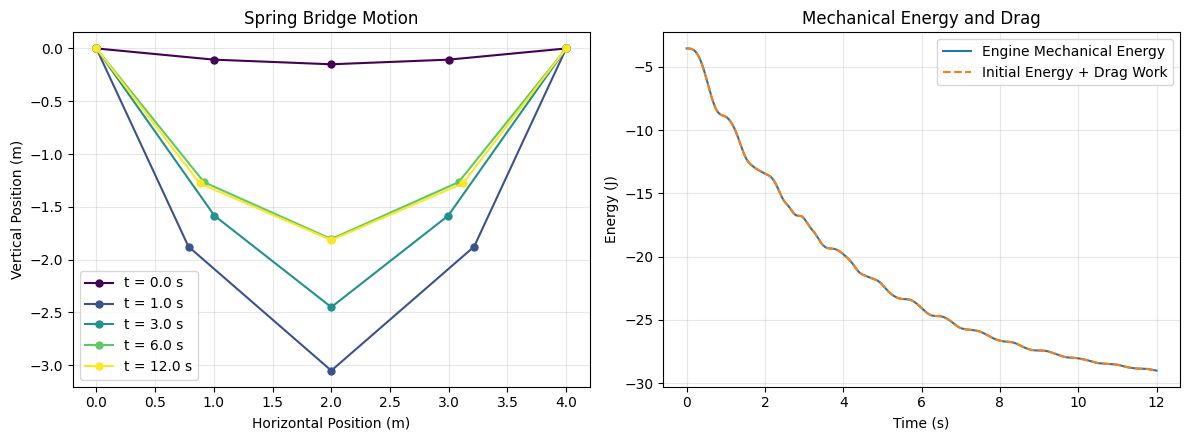

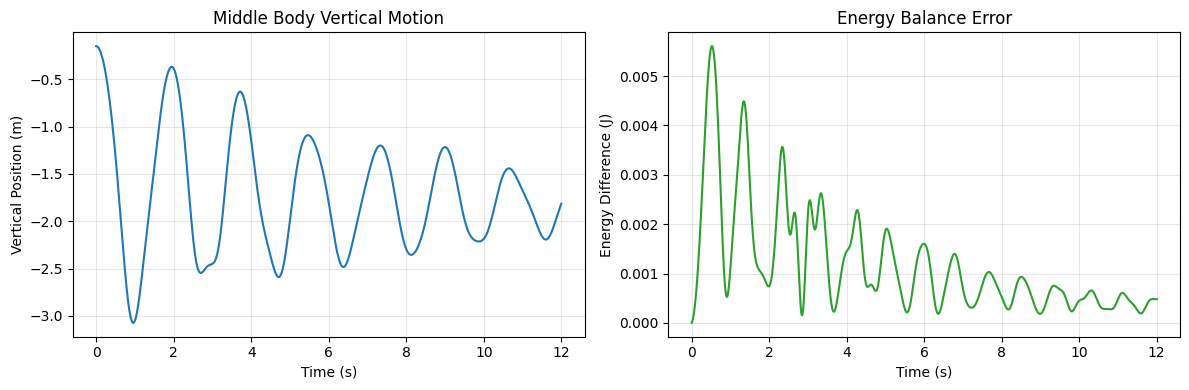


BRIDGE SETUP
Number of bodies:       5
Moving bodies:          3
Number of springs:      4
Spring constant:        35.00 N/m
Drag coefficient:       0.25 kg/s
Simulation time:        12.00 s

ENERGY RESULTS
Initial energy:         -3.551381 J
Final energy:           -29.003476 J
Change in energy:       -25.452094 J
Work done by drag:      -25.452574 J
Maximum energy error:   1.579e-03


In [19]:

# Part C - Multi-Body Spring Bridge

import numpy as np
import matplotlib.pyplot as plt

from lab07_engine import Body, World, Gravity, Drag, Spring, VelocityVerlet

print("PART C - MULTI-BODY SPRING BRIDGE")
print("-" * 55)

# Set up the bridge

N = 5
mass = 1.0
g = 9.81
k = 35.0
L0 = 1.0
drag_k = 0.25

dt = 0.001
t_end = 12.0

world = World(integrator=VelocityVerlet())

# Five bodies connected by springs
for i in range(N):

    fixed = (i == 0 or i == N - 1)

    y = 0.0 if fixed else -0.15 * np.sin(np.pi*i/(N-1))

    world.add(Body(
        m=mass,
        r=(float(i), y),
        v=(0.0, 0.0),
        fixed=fixed,
        name=f"Body {i+1}"
    ))

# Add springs between neighboring bodies
for i in range(N - 1):
    world.add_force(Spring(i, i+1, k=k, L0=L0))

world.add_force(Gravity(g=g))
world.add_force(Drag(k=drag_k, quadratic=False))

# Record positions, velocities, and energy

world.record('t', lambda w: w.t)

world.record(
    'positions',
    lambda w: np.array([b.r.copy() for b in w.bodies])
)

world.record(
    'velocities',
    lambda w: np.array([b.v.copy() for b in w.bodies])
)

world.record('E', lambda w: w.total_energy())

# Run the simulation

history = world.run(dt=dt, t_end=t_end, capture_every=10)

t = history['t']
positions = history['positions']
velocities = history['velocities']
E = history['E']

# Calculate work done by drag

# Only the three moving bodies experience drag.
speed_squared = np.sum(velocities[:, 1:-1, :]**2, axis=(1, 2))

drag_power = -drag_k * speed_squared

# Integrate power over time using the trapezoidal rule
drag_work = np.zeros(len(t))

drag_work[1:] = np.cumsum(
    0.5 * (drag_power[1:] + drag_power[:-1]) * np.diff(t)
)

# Energy should decrease by approximately the work done by drag.
energy_expected = E[0] + drag_work

energy_difference = E - energy_expected

energy_error = (
    np.max(np.abs(energy_difference)) / abs(E[0])
)

# Plot the bridge at different times

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

times_to_plot = [0, 1, 3, 6, 12]

colors = plt.cm.viridis(np.linspace(0, 1, len(times_to_plot)))

for plot_time, color in zip(times_to_plot, colors):

    index = np.argmin(np.abs(t - plot_time))

    x_pos = positions[index, :, 0]
    y_pos = positions[index, :, 1]

    ax[0].plot(
        x_pos,
        y_pos,
        'o-',
        color=color,
        label=f't = {t[index]:.1f} s',
        markersize=5
    )

ax[0].set_title("Spring Bridge Motion")
ax[0].set_xlabel("Horizontal Position (m)")
ax[0].set_ylabel("Vertical Position (m)")
ax[0].legend()
ax[0].grid(True)

ax[1].plot(
    t, E,
    label="Engine Mechanical Energy",
    color='tab:blue'
)

ax[1].plot(
    t, energy_expected,
    '--',
    label="Initial Energy + Drag Work",
    color='tab:orange'
)

ax[1].set_title("Mechanical Energy and Drag")
ax[1].set_xlabel("Time (s)")
ax[1].set_ylabel("Energy (J)")
ax[1].legend()
ax[1].grid(True)

plt.tight_layout()
plt.show()

# Plot the motion of the middle body

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

middle_x = positions[:, 2, 0]
middle_y = positions[:, 2, 1]

ax[0].plot(t, middle_y, color='tab:blue')
ax[0].set_title("Middle Body Vertical Motion")
ax[0].set_xlabel("Time (s)")
ax[0].set_ylabel("Vertical Position (m)")
ax[0].grid(True)

ax[1].plot(
    t,
    energy_difference,
    color='tab:green'
)

ax[1].set_title("Energy Balance Error")
ax[1].set_xlabel("Time (s)")
ax[1].set_ylabel("Energy Difference (J)")
ax[1].grid(True)

plt.tight_layout()
plt.show()

# Print results

print("\nBRIDGE SETUP")
print(f"Number of bodies:       {N}")
print(f"Moving bodies:          {N-2}")
print(f"Number of springs:      {N-1}")
print(f"Spring constant:        {k:.2f} N/m")
print(f"Drag coefficient:       {drag_k:.2f} kg/s")
print(f"Simulation time:        {t_end:.2f} s")

print("\nENERGY RESULTS")
print(f"Initial energy:         {E[0]:.6f} J")
print(f"Final energy:           {E[-1]:.6f} J")
print(f"Change in energy:       {E[-1]-E[0]:.6f} J")
print(f"Work done by drag:      {drag_work[-1]:.6f} J")
print(f"Maximum energy error:   {energy_error:.3e}")



## Part C Interpretation

The spring bridge behaved pretty much as expected. Once the simulation started, gravity pulled the three moving bodies downward while the springs resisted their motion. The middle body experienced the greatest displacement, reaching approximately -3.0 m before moving back upward. As time continued, the oscillations became smaller because of the drag force.

The energy results were particularly useful for checking whether the simulation was behaving correctly. The initial mechanical energy was -3.551 J, while the final energy was -29.003 J, giving a total change of -25.452 J. The calculated work done by drag was also approximately -25.453 J, which agrees very closely with the change in mechanical energy.

The maximum reported relative energy balance error was 1.579e-3, or about 0.158%. This suggests that nearly all of the mechanical energy loss was accounted for by drag, with only a small amount of numerical error.

Overall, Part C showed the biggest advantage of building a reusable physics engine. I was able to combine multiple bodies and forces into one simulation without having to rewrite how the physics was calculated!

## Lab 8 Part C1: Python Comparison

Projectile motion using Velocity Verlet with the same initial conditions,

timestep, and step count as the JavaScript simulation.

In [ ]:
import math
from lab07_engine import Body, Gravity, VelocityVerlet, World

dt = 1 / 120
steps = 240
angle = 50 * math.pi / 180

projectile = Body(
    m=1.0,
    r=(0.0, 0.0),
    v=(20 * math.cos(angle), 20 * math.sin(angle))
)

comparison_world = World(
    integrator=VelocityVerlet(),
    bodies=[projectile],
    forces=[Gravity(g=9.81)]
)

for _ in range(steps):
    comparison_world.step(dt)

python_results = {
    "x": float(projectile.r[0]),
    "y": float(projectile.r[1]),
    "vx": float(projectile.v[0]),
    "vy": float(projectile.v[1]),
    "E_total": float(comparison_world.total_energy())
}

print("C1: PYTHON RESULTS")
print(f"Steps: {steps}")
print(f"Simulated time: {steps * dt:.3f} s")

for quantity, value in python_results.items():
    print(f"{quantity:8s} = {value:.17g}")